# E3 — Coordination Graph Baseline

**Mục tiêu:** xây dựng graph dùng chung hashtag và tìm cộng đồng tài khoản bằng Louvain.

**Cách chạy:** chạy lần lượt 7 code cell trên CPU: kết nối Drive → kiểm tra input → xử lý duplicate → dựng graph và Louvain → xuất evidence → kiểm tra output → tổng hợp kết quả.

**Thiết kế:** node là tài khoản; event là một hashtag trong một giờ UTC. Giữ event có 2–100 tài khoản. Weight là số event dùng chung, giữ cạnh có weight ≥ 2. Mỗi tài khoản chỉ đóng góp một lần trong mỗi event.

**Duplicate:** loại các tweet ID có xung đột metadata/text trong audit B/C; các ID còn lại giữ bản ghi đầu tiên.

**Output:** các bảng graph, community, audit, evidence, hình minh họa, cấu hình và báo cáo trong `E3_outputs`.

**Diễn giải:** graph dùng toàn bộ corpus để phân tích mô tả. Nhãn Bad/Good chỉ dùng mô tả cộng đồng sau khi dựng graph; chưa có ground-truth campaign để đánh giá độ chính xác phát hiện chiến dịch.


In [1]:
# E3 — 1. Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# E3 — 2. Cấu hình và kiểm tra input
from pathlib import Path
import json, hashlib, sys, platform, unicodedata, math
from collections import Counter, defaultdict
from itertools import combinations
import pandas as pd
import networkx as nx
from IPython.display import display

# Đọc dữ liệu qua shortcut MXH.
BASE = Path('/content/drive/MyDrive/Colab Notebooks/MXH_4_output')
DATA = BASE / 'MXH/processed'
OUT = BASE / 'E3_outputs'
SEED = 42
WINDOW_SECONDS = 3600
MAX_USERS_PER_EVENT = 100  # bỏ event quá phổ biến, không lấy mẫu ngẫu nhiên
MIN_WEIGHT = 2  # ít nhất 2 (hashtag, giờ UTC) khác nhau cho mỗi cặp
MAX_PAIR_UPDATES = 20_000_000  # dừng rõ ràng nếu vượt RAM/time budget
FILES = [DATA/'honduras_bad_normalized.jsonl', DATA/'honduras_good_normalized.jsonl']
required = FILES + [DATA/'honduras_account_manifest.csv', DATA/'honduras_account_splits.csv']
for p in required:
    assert p.is_file(), f'Không thấy {p}. Kiểm tra Drive mount và đường dẫn DATA.'
OUT.mkdir(parents=True, exist_ok=True)
manifest = pd.read_csv(required[2], dtype={'user_id':str})
splits = pd.read_csv(required[3], dtype={'user_id':str})
assert manifest.user_id.notna().all() and manifest.user_id.is_unique
assert splits.user_id.notna().all() and splits.user_id.is_unique
assert set(manifest.user_id) == set(splits.user_id)
assert len(manifest) == 224685, 'Manifest khác phiên bản đã thống nhất; cần kiểm tra lại.'
assert splits['split'].notna().all()
assert set(splits['split']) <= {'train','validation','val','test'}
if 'label' in splits:
    check = manifest[['user_id','label']].merge(splits[['user_id','label']],on='user_id',validate='one_to_one')
    assert (check.label_x == check.label_y).all()
labels = manifest.set_index('user_id')['label'].astype(int).to_dict()
assert set(labels.values()) == {0,1}
assert Counter(labels.values()) == {0:1866,1:222819}
split_map = splits.set_index('user_id')['split'].to_dict()
print('Accounts:',len(labels), '| label 0=Bad, 1=Good')
display(splits.groupby('split').size().rename('accounts'))
for p in FILES:
    with p.open(encoding='utf-8') as f:
        sample = json.loads(next(f))
    assert {'account_id','tweet_id','created_at','hashtags','label','text'} <= sample.keys()
    print(p.name, {k:sample[k] for k in ['created_at','hashtags','label']})
print('NetworkX',nx.__version__, '| output:', OUT)


Accounts: 224685 | label 0=Bad, 1=Good


,accounts
split,
test,44938
train,157279
validation,22468


honduras_bad_normalized.jsonl {'created_at': 1576857900000, 'hashtags': [], 'label': 0}
honduras_good_normalized.jsonl {'created_at': 1578527640000, 'hashtags': ['AlivioDeDeuda'], 'label': 1}
NetworkX 3.7 | output: /content/drive/MyDrive/Colab Notebooks/MXH_4_output/E3_outputs


In [3]:
# E3 — 3. Đọc streaming, xử lý duplicate, tạo sự kiện hashtag–giờ UTC
# Exact IDs: giữ lần đầu. Toàn bộ occurrence của metadata/text-conflict IDs: loại.
from datetime import datetime, timezone
import re
AUDIT = DATA/'quality_audit'
conflicts = set()
for name in ['group_b_metadata_conflicts.csv','group_c_text_conflicts.csv']:
    p = AUDIT/name
    assert p.is_file(), f'Thiếu audit bắt buộc: {p}'
    q = pd.read_csv(p, dtype=str)
    assert 'tweet_id' in q.columns
    conflicts.update(q.tweet_id.dropna())

def timestamp_seconds(value):
    if value is None or value == '':
        return None
    s = str(value).strip()
    try:
        if s.lstrip('-').replace('.', '', 1).isdigit():
            x = float(s)
            if abs(x) > 1e11: x /= 1000
            return int(x) if 946684800 <= x <= 4102444800 else None
        d = datetime.fromisoformat(s.replace('Z','+00:00'))
        if d.tzinfo is None: d = d.replace(tzinfo=timezone.utc)
        return int(d.timestamp())
    except (ValueError, OverflowError):
        t = pd.to_datetime(s, utc=True, errors='coerce')
        return None if pd.isna(t) else int(t.timestamp())

def tags_of(value):
    assert isinstance(value, list), f'hashtags cần là list, nhận {type(value)}'
    result = set()
    for item in value:
        if isinstance(item, dict): item = item.get('text', item.get('tag',''))
        assert isinstance(item, str), 'Hashtag sai schema'
        tag = unicodedata.normalize('NFKC', item).strip().lstrip('#').casefold()
        if tag: result.add(tag)
    return sorted(result)

events = defaultdict(set)
seen = set()
observed_accounts = set()
quality = Counter()
source_rows = Counter()
input_hashes = {}
for file_index, p in enumerate(FILES):
    sha = hashlib.sha256()
    with p.open('rb') as f:
        for line_no, raw in enumerate(f, 1):
            sha.update(raw)
            if not raw.strip(): continue
            obj = json.loads(raw)
            quality['raw_rows'] += 1
            source_rows[p.name] += 1
            aid, tid = str(obj['account_id']), str(obj['tweet_id'])
            assert aid in labels, f'Account không nằm trong manifest: {aid}'
            assert int(obj['label']) == labels[aid] == file_index
            observed_accounts.add(aid)
            if tid in conflicts:
                quality['conflict_rows_removed'] += 1
                continue
            assert tid not in ('','None','nan'), 'Missing tweet ID'
            if tid in seen:
                quality['duplicate_rows_removed'] += 1
                continue
            seen.add(tid)
            ts = timestamp_seconds(obj['created_at'])
            if ts is None:
                quality['invalid_timestamp_rows'] += 1
                continue
            quality['retained_valid_rows'] += 1
            tags = tags_of(obj.get('hashtags') or [])
            if not tags: quality['rows_without_hashtag'] += 1
            for tag in tags:
                events[(tag, ts // WINDOW_SECONDS)].add(aid)
    input_hashes[p.name] = sha.hexdigest()
    print(p.name, 'rows:',source_rows[p.name])
assert observed_accounts == set(labels), 'Account coverage không khớp manifest'
assert list(source_rows.values()) == [137252,1125578], 'Số record khác phiên bản đã audit'
quality['conflict_ids_excluded'] = len(conflicts)
quality['unique_retained_tweet_ids'] = len(seen)
quality['hashtag_time_events'] = len(events)
pd.DataFrame(sorted(quality.items()),columns=['metric','value']).to_csv(OUT/'e3_data_quality.csv',index=False)
display(pd.Series(quality))
print('Ví dụ event:', next(iter(events.items()), None))


honduras_bad_normalized.jsonl rows: 137252
honduras_good_normalized.jsonl rows: 1125578


,0
raw_rows,1262830
retained_valid_rows,1254185
rows_without_hashtag,237730
conflict_rows_removed,1362
duplicate_rows_removed,7283
conflict_ids_excluded,389
unique_retained_tweet_ids,1254185
hashtag_time_events,403043


Ví dụ event: (('ciudadmujerjuticalpa', 437330), {'1196133629333770240', '1191091027446239232', '1191088594884210688', '1191725807275778048', '1196134831723352064', '1191149569503121408', '1192984606590603264', '1182491964970807296', '1194990564942516224', '1194989483265015808', '1191141101421387776', '1183414966411583488', '1191136071742107648', '1191144767649992704', '1191511547790671872', '1191513076530634752', '1192989258195361792', '1191107773041385472', '1194977727683661824', '1191514778952491008', '1191152148190511104', '1191790017519267840', '1191504807724552192', '1190303283329617927', '1192973444952084480', '1191157216608432128', '1191105781560758272', '1191734068049784832', '1196136910546251776', '392378363', '1194984475161182208', '1196110974199181312', '1187084594874585091', '1191509273551032320', '1191785669074534400', '1196135883772174336', '1192953832956977152', '1191103288424439808', '1192986463585079296', '1191155384846864384', '1191516349664768000', '11915189775850250

In [4]:
# E3 — 4. Dựng graph vô hướng có trọng số và chạy Louvain
# Mỗi account tính một lần/event (hashtag, giờ UTC).
# Weight là số event dùng chung; chỉ giữ cạnh đạt MIN_WEIGHT.
pair_weights = Counter()
event_audit = []
pair_updates = 0
for (tag, bucket), users in sorted(events.items()):
    n = len(users)
    status = 'kept' if 2 <= n <= MAX_USERS_PER_EVENT else ('singleton' if n < 2 else 'too_popular')
    event_audit.append((tag,bucket,n,status))
    if status != 'kept': continue
    pair_updates += n*(n-1)//2
    if pair_updates > MAX_PAIR_UPDATES:
        raise RuntimeError('Vượt pair budget. Giảm MAX_USERS_PER_EVENT và chạy lại từ cell 4; ghi rõ cấu hình mới.')
    pair_weights.update(combinations(sorted(users),2))
edge_rows = [(a,b,w) for (a,b),w in sorted(pair_weights.items()) if w >= MIN_WEIGHT]
edges = pd.DataFrame(edge_rows,columns=['source','target','weight'])
G = nx.Graph()
G.add_nodes_from(sorted(labels))
G.add_weighted_edges_from(edge_rows)
assert nx.number_of_selfloops(G) == 0
H = nx.Graph()
H.add_nodes_from(sorted(n for n, d in G.degree() if d > 0))
H.add_weighted_edges_from(sorted(
    (min(u, v), max(u, v), data["weight"])
    for u, v, data in G.edges(data=True)
))
if H.number_of_edges():
    communities = nx.community.louvain_communities(H,weight='weight',resolution=1,seed=SEED)
    communities = sorted(communities,key=lambda c:(-len(c),min(c)))
    modularity = nx.community.modularity(H,communities,weight='weight',resolution=1)
else:
    communities, modularity = [], None
membership = {u:i for i,c in enumerate(communities) for u in c}
nodes = pd.DataFrame([dict(account_id=u,label=labels[u],split=split_map[u],
    degree=G.degree(u),strength=G.degree(u,weight='weight'),
    community=membership.get(u,-1)) for u in sorted(G)])
# -1 = isolate, không gom tất cả isolate thành một community thật.
components = sorted(nx.connected_components(G),key=lambda c:(-len(c),min(c)))
metrics = dict(experiment='E3',method='hashtag_hour_louvain',scope='full_corpus_descriptive_transductive',
    seed=SEED,window_seconds=WINDOW_SECONDS,max_users_per_event=MAX_USERS_PER_EVENT,
    min_weight=MIN_WEIGHT,n_nodes=len(G),n_active_nodes=len(H),n_edges=G.number_of_edges(),
    n_isolates=nx.number_of_isolates(G),density=nx.density(G),
    n_components=len(components),largest_component_nodes=len(components[0]) if components else 0,
    n_communities=len(communities),largest_community_nodes=len(communities[0]) if communities else 0,
    modularity=modularity,pair_updates=pair_updates,
    dropped_popular_events=sum(r[3]=='too_popular' for r in event_audit))
edges.to_csv(OUT/'e3_graph_edges.csv',index=False)
nodes.to_csv(OUT/'e3_graph_nodes.csv',index=False)
pd.DataFrame([metrics]).to_csv(OUT/'e3_graph_metrics.csv',index=False)
pd.DataFrame(event_audit,columns=['hashtag','time_bucket','n_accounts','status']).to_csv(OUT/'e3_event_audit.csv',index=False)
pd.DataFrame([(i,len(c)) for i,c in enumerate(components)],columns=['component','n_nodes']).to_csv(OUT/'e3_components.csv',index=False)
display(pd.DataFrame([metrics]).T)
print('Louvain chạy trên active graph; isolate vẫn được lưu trong node table.')


,0
experiment,E3
method,hashtag_hour_louvain
scope,full_corpus_descriptive_transductive
seed,42
window_seconds,3600
max_users_per_event,100
min_weight,2
n_nodes,224685
n_active_nodes,84819
n_edges,1905386


Louvain chạy trên active graph; isolate vẫn được lưu trong node table.


In [5]:
# E3 — 5. Community summary và bằng chứng để kiểm tra thủ công
summary_rows = []
for cid, c in enumerate(communities):
    sub = H.subgraph(c)
    bad = sum(labels[u]==0 for u in c)
    summary_rows.append(dict(community=cid,n_nodes=len(c),n_edges=sub.number_of_edges(),
        density=nx.density(sub),bad_accounts=bad,good_accounts=len(c)-bad,bad_ratio=bad/len(c)))
summary = pd.DataFrame(summary_rows,columns=['community','n_nodes','n_edges','density','bad_accounts','good_accounts','bad_ratio'])
summary.to_csv(OUT/'e3_communities.csv',index=False)
display(summary.head(10))
# Chọn tối đa 3 community lớn nhất, cạnh mạnh nhất mỗi community (tie-break ID).
picked = []
for cid,c in enumerate(communities[:3]):
    candidate = sorted(((a,b,d['weight']) for a,b,d in H.subgraph(c).edges(data=True)),key=lambda r:(-r[2],r[0],r[1]))
    if candidate: picked.append((cid,*candidate[0]))
targets = defaultdict(list)
for cid,a,b,w in picked:
    shared = [(tag,bucket) for (tag,bucket),us in sorted(events.items())
              if 2 <= len(us) <= MAX_USERS_PER_EVENT and a in us and b in us][:3]
    assert len(shared) >= min(3,w)
    for tag,bucket in shared:
        for aid in [a,b]: targets[(aid,tag,bucket)].append((cid,a,b,w))
evidence, used_ids, captured = [], set(), set()
for p in FILES:
    with p.open(encoding='utf-8') as f:
        for raw in f:
            if not raw.strip(): continue
            obj = json.loads(raw)
            tid, aid = str(obj['tweet_id']), str(obj['account_id'])
            if tid in conflicts or tid in used_ids: continue
            used_ids.add(tid)
            ts = timestamp_seconds(obj['created_at'])
            if ts is None: continue
            for tag in tags_of(obj.get('hashtags') or []):
                key = (aid,tag,ts//WINDOW_SECONDS)
                if key not in targets or key in captured: continue
                captured.add(key)
                for cid,a,b,w in targets[key]:
                    evidence.append(dict(community=cid,source=a,target=b,weight=w,
                        hashtag=tag,time_bucket=key[2],account_id=aid,tweet_id=tid,
                        created_at=str(obj['created_at']),text=obj['text'],
                        review_status='pending',review_note=''))
review = pd.DataFrame(evidence,columns=['community','source','target','weight','hashtag','time_bucket',
    'account_id','tweet_id','created_at','text','review_status','review_note'])
assert set(targets) <= captured, 'Thiếu evidence cho một số event'
review.to_csv(OUT/'e3_manual_review.csv',index=False)
display(review)
print('Đọc từng cặp text/time/hashtag; điền review_status và review_note trong CSV.')
print('Không tự đánh dấu đã review. Hashtag/time trùng có thể là tin tức hoặc hoạt động tự nhiên.')


,community,n_nodes,n_edges,density,bad_accounts,good_accounts,bad_ratio
0,0,17486,385856,0.002524,1,17485,0.000057
1,1,12386,80986,0.001056,0,12386,0.000000
2,2,12118,300186,0.004089,0,12118,0.000000
3,3,10659,377948,0.006654,0,10659,0.000000
4,4,3934,25764,0.003330,34,3900,0.008643
5,5,2789,36187,0.009308,0,2789,0.000000
6,6,1855,27306,0.015879,0,1855,0.000000
7,7,1835,41266,0.024524,752,1083,0.409809
8,8,1515,12586,0.010974,0,1515,0.000000
9,9,1031,17243,0.032475,0,1031,0.000000


,community,source,target,weight,hashtag,time_bucket,account_id,tweet_id,created_at,text,review_status,review_note
0,2,955569674737127425,1071499269880901639,53,2ene,438338,955569674737127425,1212917957199876096,1578017100000,RT @ChalecosAmarill: 📽🆘️ #2Ene || #Irak 🇮🇶\n\n...,pending,
1,2,955569674737127425,1071499269880901639,53,2ene,438338,1071499269880901639,1212917807488360449,1578017100000,RT @ChalecosAmarill: 📽🆘️ #2Ene || #Irak 🇮🇶\n\n...,pending,
2,2,955569674737127425,1071499269880901639,53,alerta,438337,955569674737127425,1212915629168250880,1578016560000,RT @ChalecosAmarill: 🚨 #ALERTA 🚨 ‼️FURIA CONTR...,pending,
3,2,955569674737127425,1071499269880901639,53,alerta,438337,1071499269880901639,1212915436502835207,1578016500000,🚨 #ALERTA 🚨 ‼️FURIA CONTRA #EEUU 🇺🇸‼️\n\n#USA ...,pending,
4,2,955569674737127425,1071499269880901639,53,2ene,438337,1071499269880901639,1212911628448149504,1578015600000,RT @ChalecosAmarill: 📽🆘️ #2Ene || ⚠️ #ALERTA ⚠...,pending,
5,2,955569674737127425,1071499269880901639,53,2ene,438337,955569674737127425,1212901449837006848,1578013200000,RT @ChalecosAmarill: 📽🆘️ #2Ene || ⚠️ #ALERTA ⚠...,pending,
6,0,141160059,145459615,177,10nov,437058,145459615,1193603688025210880,1573412220000,¡ENTÉRATE! Descubre las 4 maneras de lograr se...,pending,
7,0,141160059,145459615,177,10nov,437058,141160059,1193595641269833730,1573410300000,RT @DolarToday: ¡ULTIMA HORA! Capturan a Hugo ...,pending,
8,0,141160059,145459615,177,10nov,437053,141160059,1193527460232671233,1573394040000,RT @DolarToday: ¡ULTIMA HORA! Capturan a Hugo ...,pending,
9,0,141160059,145459615,177,10nov,437053,145459615,1193527332998451201,1573394040000,¡ULTIMA HORA! Capturan a Hugo Carvajal y lo ex...,pending,


Đọc từng cặp text/time/hashtag; điền review_status và review_note trong CSV.
Không tự đánh dấu đã review. Hashtag/time trùng có thể là tin tức hoặc hoạt động tự nhiên.


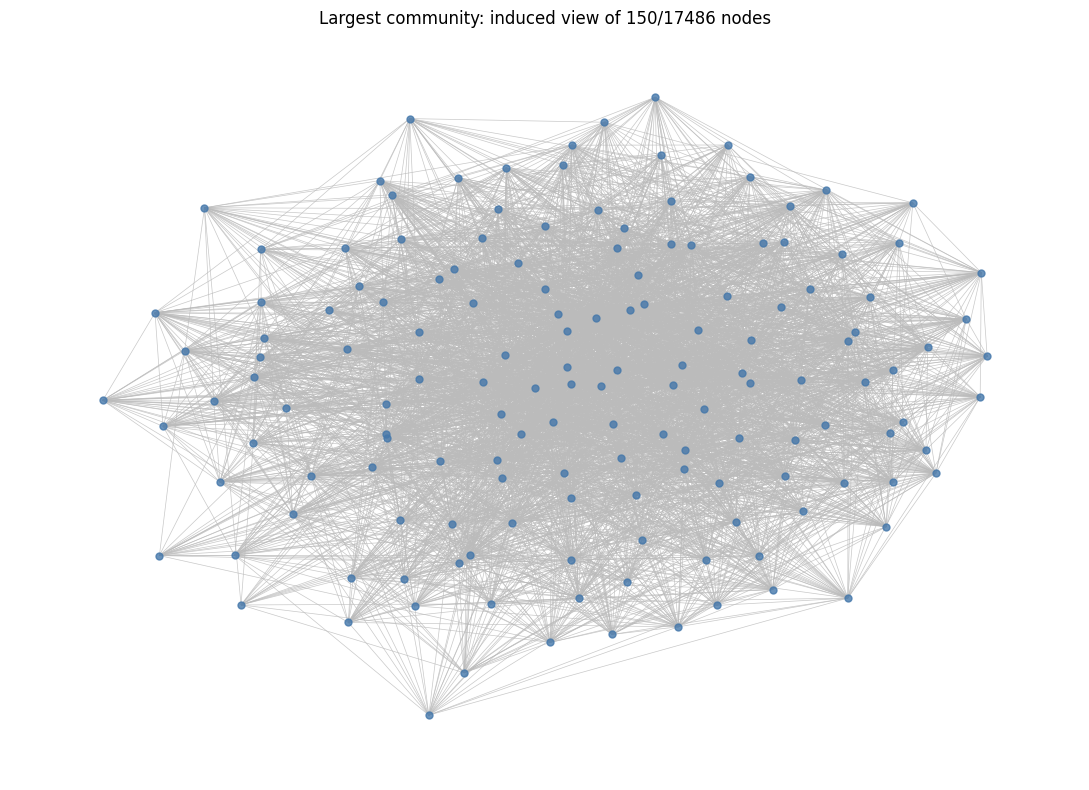

PASS: output reload checks. Kết quả: /content/drive/MyDrive/Colab Notebooks/MXH_4_output/E3_outputs
E3_RESULTS.md 2218 bytes
README.md 4269 bytes
e3_communities.csv 47273 bytes
e3_community_preview.png 1521752 bytes
e3_components.csv 1164710 bytes
e3_data_quality.csv 228 bytes
e3_event_audit.csv 11234284 bytes
e3_graph_edges.csv 56096937 bytes
e3_graph_metrics.csv 429 bytes
e3_graph_nodes.csv 6493548 bytes
e3_manual_review.csv 5652 bytes
e3_manual_review.gsheet 177 bytes
e3_run_config.json 1288 bytes
e3_split_counts.csv 58 bytes
requirements_e3.txt 47 bytes


In [6]:
# E3 — 6. Hình minh họa, kiểm tra output và README tái lập
import matplotlib.pyplot as plt
import importlib.metadata as metadata
# Chỉ minh họa tối đa 150 node có weighted degree cao trong community lớn nhất.
# Thống kê ở cell 4/5 vẫn tính trên graph đầy đủ.
if communities:
    chosen = sorted(communities[0],key=lambda u:(-H.degree(u,weight='weight'),u))[:150]
    P = H.subgraph(sorted(chosen)).copy()
    plt.figure(figsize=(11,8))
    pos = nx.spring_layout(P,seed=SEED,weight='weight')
    nx.draw_networkx(P,pos,node_size=25,with_labels=False,
        node_color='#4477AA',edge_color='#BBBBBB',width=0.5,alpha=0.8)
    plt.title(f'Largest community: induced view of {len(P)}/{len(communities[0])} nodes')
    plt.axis('off'); plt.tight_layout()
    plt.savefig(OUT/'e3_community_preview.png',dpi=180)
    plt.show()
# Kiểm tra reload IDs dưới dạng string để tránh mất chính xác tweet/account IDs.
echeck = pd.read_csv(OUT/'e3_graph_edges.csv',dtype={'source':str,'target':str})
ncheck = pd.read_csv(OUT/'e3_graph_nodes.csv',dtype={'account_id':str})
assert len(echeck) == G.number_of_edges()
assert ncheck.account_id.is_unique and set(ncheck.account_id)==set(labels)
assert (echeck.weight >= MIN_WEIGHT).all()
assert (echeck.source != echeck.target).all()
assert sum(ncheck.degree) == 2*len(echeck)
assert (ncheck['label'].astype(int) == ncheck.account_id.map(labels)).all()
assert (ncheck['split'] == ncheck.account_id.map(split_map)).all()
for p in required[2:] + sorted(AUDIT.glob('group_*.csv')):
    input_hashes[str(p.relative_to(DATA))] = hashlib.sha256(p.read_bytes()).hexdigest()
config = dict(seed=SEED,window_seconds=WINDOW_SECONDS,max_users_per_event=MAX_USERS_PER_EVENT,
    min_weight=MIN_WEIGHT,max_pair_updates=MAX_PAIR_UPDATES,
    graph_scope='full corpus, descriptive/transductive; no held-out predictive score',
    duplicate_policy='drop all B/C conflict IDs; retain first occurrence of other tweet IDs',
    label_mapping={'0':'Bad','1':'Good'},input_sha256=input_hashes,
    python=platform.python_version(),packages={p:metadata.version(p) for p in ['networkx','pandas','matplotlib']})
(OUT/'e3_run_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'requirements_e3.txt').write_text(''.join(p+'=='+v+chr(10) for p,v in config['packages'].items()),encoding='utf-8')
README = f'''# E3 — Coordination Graph Baseline
## Chạy lại
1. Mở E3_Coordination_Graph.ipynb trên Colab, dùng CPU runtime.
2. Chạy cell 1 và hoàn tất Google Drive mount bằng tài khoản có quyền đọc MXH.
3. DATA ở cell 2 trỏ đến MXH/processed qua shortcut trong MXH_4_output.
   Có thể sửa DATA nếu shortcut nằm ở vị trí khác. OUT hiện tại: {OUT}
4. Chạy lần lượt cell 2 → 7.
5. Kiểm tra bảng metrics, community summary và e3_manual_review.csv.
   Điền review_status/review_note sau khi thực sự đọc evidence.
6. Lưu notebook bằng Ctrl+S. Outputs riêng tư của Colab có thể không nằm trong ipynb;
   các CSV/JSON/PNG được lưu riêng ở OUT.

## Input
Hai Honduras normalized JSONL, honduras_account_manifest.csv,
honduras_account_splits.csv, quality_audit/group_b_metadata_conflicts.csv,
quality_audit/group_c_text_conflicts.csv. Không cần Fox8 hay feature table E2.
Schema: account_id, tweet_id, label, text, created_at, hashtags.
Label 0=Bad, 1=Good; nhãn chỉ dùng mô tả hậu nghiệm, không dùng tạo graph.
File gốc chỉ đọc. Conflict IDs B/C bị loại toàn bộ; ID còn lại giữ occurrence đầu.

## Định nghĩa graph
Node: mọi account trong manifest, giữ cả isolate.
Event: một hashtag NFKC/casefold, bỏ # đầu, trong giờ UTC cố định 3600 giây.
Mỗi account chỉ tính một lần/event. Event có 2–{MAX_USERS_PER_EVENT} account mới được dùng.
Edge vô hướng: hai account cùng event; weight là số event khác nhau dùng chung.
Giữ weight >= {MIN_WEIGHT}, không self-loop. Không giới hạn số tweet theo label.
Louvain: NetworkX, weighted, resolution=1, seed={SEED}, chạy trên active nodes.
Community -1 trong node table là isolate, không phải một community thật.

## Output
- e3_graph_edges.csv: source,target,weight
- e3_graph_nodes.csv: account_id,label,split,degree,strength,community
- e3_graph_metrics.csv: node/edge/isolate/component/community statistics, modularity
- e3_communities.csv, e3_components.csv: bảng thống kê
- e3_data_quality.csv, e3_event_audit.csv: số record bị loại và event bị bỏ
- e3_manual_review.csv: evidence của cạnh mạnh nhất trong tối đa 3 community lớn
- e3_community_preview.png: hình một phần community lớn nhất nếu graph có cạnh
- e3_run_config.json: cấu hình, SHA256 input và phiên bản runtime
- requirements_e3.txt: phiên bản package của lần chạy

## Giới hạn và cách diễn giải
Đây là baseline shared-hashtag coordination/community discovery, chưa xác nhận campaign.
Không có ground-truth campaign labels nên không báo Precision/Recall/F1 campaign.
Modularity và bad_ratio chỉ là mô tả, không chứng minh phối hợp độc hại.
Hashtag phổ biến, tin nóng, retweet cùng nội dung và chênh lệch mức hoạt động có thể tạo cạnh tự nhiên.
Giờ cố định có boundary effect; cùng hashtag ở hai giờ liền kề không nối nhau.
Ngưỡng event tối đa bỏ cả event phổ biến, làm mất một phần tín hiệu; audit ghi rõ số bị bỏ.
Threshold được khai báo trước, không chọn theo label/test. Chưa thực hiện sensitivity analysis.
Graph dùng toàn corpus (transductive/mô tả), giữ split làm metadata, không thay split E1/E2.
Không dùng graph này cho đánh giá inductive E2 nếu chưa thiết kế lại quy trình tránh leakage.
Nếu graph rỗng: báo đúng 0 cạnh; không âm thầm giảm ngưỡng để tạo kết quả đẹp.
Nếu vượt pair budget: chương trình dừng, không xuất graph cắt cụt; sửa cấu hình và chạy lại.

## Reproducibility checklist
[x] Kiểm tra số account và label, manifest/split không giao nhau theo account.
[x] Không dùng label hoặc split để chọn cạnh.
[x] Duplicate policy và input hashes được ghi lại.
[x] Seed và thứ tự node/edge được cố định.
[x] Reload output kiểm tra ID, degree, split, label.
[ ] Người thực hiện xác nhận review thủ công trong CSV.
[ ] Thành viên khác chạy toàn bộ trên runtime sạch và đối chiếu output.
'''
(OUT/'README.md').write_text(README,encoding='utf-8')
print('PASS: output reload checks. Kết quả:',OUT)
for p in sorted(OUT.iterdir()): print(p.name, p.stat().st_size, 'bytes')

split_counts = splits.groupby('split').size().to_dict()
pd.DataFrame(sorted(split_counts.items()),columns=['split','n_accounts']).to_csv(OUT/'e3_split_counts.csv',index=False)


In [7]:
# E3 — 7. Hiển thị evidence đầy đủ để review
print(json.dumps(metrics,ensure_ascii=False,indent=2))
for r in review.to_dict('records'):
    print(json.dumps({k:r[k] for k in ['community','source','target','weight','hashtag','time_bucket','account_id','tweet_id','created_at','text']},ensure_ascii=False))

# Nhận xét cho các cặp evidence đã kiểm tra.
# Khóa theo account pair để không gán nhầm nếu community ID thay đổi khi chạy lại.
review_notes = {
    tuple(sorted(['955569674737127425','1071499269880901639'])):
        'Đã đọc 3 event mẫu: hai account chia sẻ nội dung của ChalecosAmarill; một event cùng timestamp ghi nhận, một lệch 60 giây, một lệch 40 phút. Có shared amplification nhưng chưa chứng minh campaign độc hại.',
    tuple(sorted(['145459615','141160059'])):
        'Đã đọc 3 event mẫu: hai event có nội dung DolarToday giống/gần giống dạng original–retweet; event #10nov ở bucket 437058 có text khác chủ đề. Hashtag ngày tháng có thể tạo cạnh yếu về ngữ nghĩa.',
    tuple(sorted(['149310384','311680564'])):
        'Đã đọc 3 event #aliado: nội dung tin dầu mỏ gần giống nhau, cùng timestamp ghi nhận ở mỗi event, khác URL rút gọn. Phù hợp giả thuyết đăng lại/syndication; không đủ kết luận malicious coordination.'
}
review['reviewer'] = ''
for idx,r in review.iterrows():
    key = tuple(sorted([r['source'],r['target']]))
    if key in review_notes:
        review.loc[idx,'review_status'] = 'reviewed_evidence_only'
        review.loc[idx,'review_note'] = review_notes[key]
        review.loc[idx,'reviewer'] = 'ChatGPT assisted inspection 2026-10-18'
review.to_csv(OUT/'e3_manual_review.csv',index=False)
report = f"""# E3 — Kết quả baseline
Dữ liệu: {quality['raw_rows']:,} records ban đầu; giữ {quality['retained_valid_rows']:,} tweet hợp lệ sau lọc.
Loại {quality['conflict_rows_removed']:,} rows của {len(conflicts)} conflict IDs và {quality['duplicate_rows_removed']:,} rows trùng còn lại.
Node: {len(G):,}; active: {len(H):,}; isolate: {nx.number_of_isolates(G):,}.
Cạnh: {G.number_of_edges():,}; components: {len(components):,}; cộng đồng active: {len(communities):,}.
Modularity weighted: {modularity}; community lớn nhất: {len(communities[0]) if communities else 0:,} node.
Bỏ {metrics['dropped_popular_events']:,} event có hơn {MAX_USERS_PER_EVENT} account.
Graph dùng hashtag–giờ UTC, minimum weight {MIN_WEIGHT}; Louvain seed {SEED}.

## Review mẫu đã đọc
"""
for pair,note in review_notes.items():
    selected = review[(review.source.isin(pair)) & (review.target.isin(pair))]
    if not selected.empty:
        report += chr(10)+str(pair)+': '+note+chr(10)
report += """
## Diễn giải và giới hạn
Một tweet có nhiều hashtag có thể đóng góp nhiều event cho cùng cặp; weight KHÔNG phải số lần phối hợp độc lập.
Hashtag ngày tháng/tin nóng và nguồn tin dùng chung có thể tạo nhiều cạnh tự nhiên.
Timestamp chỉ chính xác ở mức dữ liệu ghi nhận; cùng timestamp không chứng minh cùng giây đăng thực tế.
Ba cặp được chọn từ ba community lớn nhất, cạnh mạnh nhất, không đại diện ngẫu nhiên cho toàn graph.
Đã kiểm tra evidence, chưa có xác minh người dùng thật hay ground-truth campaign.
Bad/Good là nhãn account, không phải nhãn campaign. Không diễn giải modularity thành độ chính xác.
Chưa thực hiện transfer-learning graph, ablation, sensitivity analysis hoặc đánh giá classifier.
"""
(OUT/'E3_RESULTS.md').write_text(report,encoding='utf-8')
readme = (OUT/'README.md').read_text(encoding='utf-8')
readme += chr(10)+'## Assisted evidence review'+chr(10)+'Xem E3_RESULTS.md và e3_manual_review.csv. Ba cặp/18 dòng đã được đọc; reviewed_evidence_only không phải nhãn malicious. Human validation vẫn cần nếu đưa ra kết luận campaign.'+chr(10)
(OUT/'README.md').write_text(readme,encoding='utf-8')
print(report)
print('Review status:',review.review_status.value_counts().to_dict())
display(summary.head(10))


{
  "experiment": "E3",
  "method": "hashtag_hour_louvain",
  "scope": "full_corpus_descriptive_transductive",
  "seed": 42,
  "window_seconds": 3600,
  "max_users_per_event": 100,
  "min_weight": 2,
  "n_nodes": 224685,
  "n_active_nodes": 84819,
  "n_edges": 1905386,
  "n_isolates": 139866,
  "density": 7.548605667187969e-05,
  "n_components": 141752,
  "largest_component_nodes": 79404,
  "n_communities": 2104,
  "largest_community_nodes": 17486,
  "modularity": 0.6546230630786463,
  "pair_updates": 12325797,
  "dropped_popular_events": 3536
}
{"community": 2, "source": "955569674737127425", "target": "1071499269880901639", "weight": 53, "hashtag": "2ene", "time_bucket": 438338, "account_id": "955569674737127425", "tweet_id": "1212917957199876096", "created_at": "1578017100000", "text": "RT @ChalecosAmarill: 📽🆘️ #2Ene || #Irak 🇮🇶\n\n♾A pesar de que han pasado horas desde el ataque de los manifestantes iraquíes a la embajada de…"}
{"community": 2, "source": "955569674737127425", "targ

,community,n_nodes,n_edges,density,bad_accounts,good_accounts,bad_ratio
0,0,17486,385856,0.002524,1,17485,0.000057
1,1,12386,80986,0.001056,0,12386,0.000000
2,2,12118,300186,0.004089,0,12118,0.000000
3,3,10659,377948,0.006654,0,10659,0.000000
4,4,3934,25764,0.003330,34,3900,0.008643
5,5,2789,36187,0.009308,0,2789,0.000000
6,6,1855,27306,0.015879,0,1855,0.000000
7,7,1835,41266,0.024524,752,1083,0.409809
8,8,1515,12586,0.010974,0,1515,0.000000
9,9,1031,17243,0.032475,0,1031,0.000000
